Week 4 libraries loaded. Ready for classification!
Target variable: price_up (Binary Classification)
Features we are using: ['open', 'high', 'low', 'volume']
Data scaled successfully with StandardScaler!

--- Logistic Regression Results ---
Accuracy Score: 0.8094

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.87      0.82       606
           1       0.85      0.75      0.80       590

    accuracy                           0.81      1196
   macro avg       0.81      0.81      0.81      1196
weighted avg       0.81      0.81      0.81      1196



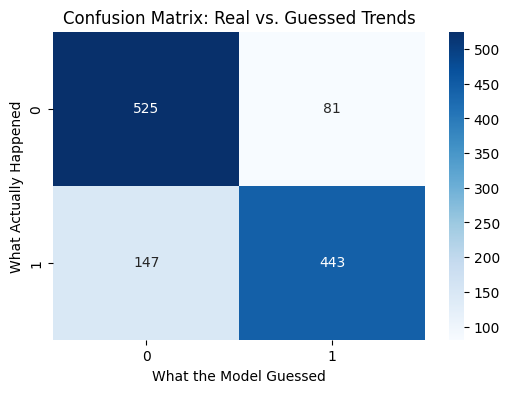

In [1]:
# Step 1: Get the libraries ready for Week 4 (Logistic Regression and Scaling)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Week 4 libraries loaded. Ready for classification!")

# Step 2: Load our trusted natural gas dataset from GitHub
link_gas = "https://raw.githubusercontent.com/JSFranco-DS/DX699S/main/Natural_Gas_data.csv"
df_gas = pd.read_csv(link_gas)

# Step 3: Change our target variable into a binary outcome (0 or 1) for Logistic Regression
# Because logistic regression needs categories, we make a simple rule:
# 1 if the 'close' price went up compared to yesterday, 0 if it went down or stayed flat.
df_gas['price_up'] = (df_gas['close'].diff() > 0).astype(int)

# drop empty rows created by the .diff() math
df_gas = df_gas.dropna()

# Pick the numeric features from the dataset
y_original = 'close'
num_cols = df_gas.select_dtypes(include=[np.number]).columns.tolist()

# take out the original price and our new target so we don't accidentally cheat
if y_original in num_cols:
    num_cols.remove(y_original)
if 'price_up' in num_cols:
    num_cols.remove('price_up')

# Let's just grab the first 4 numeric columns to keep it simple
X = df_gas[num_cols[:4]]
y = df_gas['price_up'] # Our new binary target

print("Target variable: price_up (Binary Classification)")
print("Features we are using:", X.columns.tolist())

# Step 4: Split data into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 5: Feature Scaling (Standardization / Z-score)
# This is super important so all features have equal sizing before we train the model!
my_scaler = StandardScaler()
X_train_scaled = my_scaler.fit_transform(X_train)
X_test_scaled = my_scaler.transform(X_test)

print("Data scaled successfully with StandardScaler!")

# Step 6: Train the Logistic Regression Model
my_log_model = LogisticRegression(random_state=42)
my_log_model.fit(X_train_scaled, y_train)

# Step 7: Evaluate how well the model guessed
test_guess = my_log_model.predict(X_test_scaled)

print("\n--- Logistic Regression Results ---")
print(f"Accuracy Score: {accuracy_score(y_test, test_guess):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, test_guess))

# Step 8: Draw a Confusion Matrix to visualize the true vs. false guesses
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, test_guess), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix: Real vs. Guessed Trends')
plt.xlabel('What the Model Guessed')
plt.ylabel('What Actually Happened')
plt.show()